# Landsat8 full-test rate–distortion results
1700-image full test set. Hybrid values are the current completed 400-epoch results until the 600-epoch run finishes.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
DATA = Path('../data/full_test_rd_all_methods.csv')
rd = pd.read_csv(DATA)
data = rd[rd.Dataset.eq('landsat8')].sort_values(['Method', 'bpp'])
display(data[['Method','Lambda','images','bpp','psnr','ms_ssim_db']].reset_index(drop=True))

,Method,Lambda,images,bpp,psnr,ms_ssim_db
0,elic,1024,1700,0.077988,37.733338,15.081017
1,elic,2048,1700,0.128864,39.409542,16.611143
2,elic,4096,1700,0.203836,41.266181,18.706238
3,elic,8192,1700,0.327262,43.360296,20.930868
4,elic,16384,1700,0.532089,45.215340,22.912959
5,elic,32768,1700,0.833082,47.074432,25.075293
6,elic,65536,1700,1.192100,48.565628,26.957563
7,ftic,1024,1700,0.048823,39.449817,15.707514
8,ftic,2048,1700,0.090493,40.676683,17.232511
9,ftic,4096,1700,0.152035,41.381750,18.667180


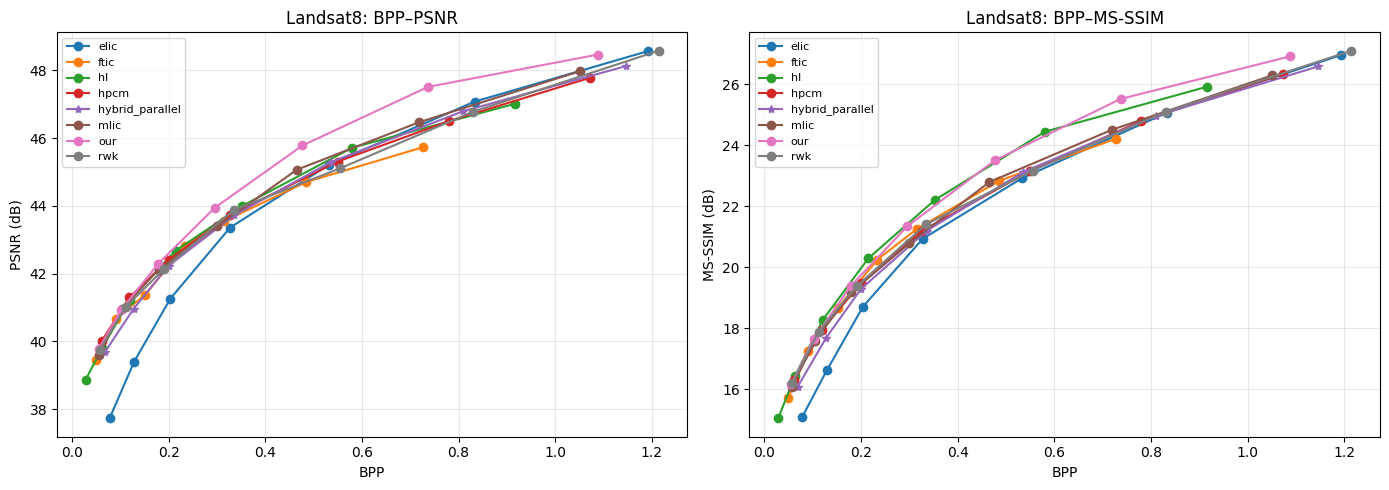

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for method, group in data.groupby('Method'):
    group = group.sort_values('bpp')
    marker = '*' if method == 'hybrid_parallel' else 'o'
    axes[0].plot(group.bpp, group.psnr, marker=marker, label=method)
    axes[1].plot(group.bpp, group.ms_ssim_db, marker=marker, label=method)
axes[0].set(xlabel='BPP', ylabel='PSNR (dB)', title='Landsat8: BPP–PSNR')
axes[1].set(xlabel='BPP', ylabel='MS-SSIM (dB)', title='Landsat8: BPP–MS-SSIM')
for ax in axes:
    ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()